# Car Evaluation Classification

Revised from Nivedha Sivakumar's saved learning project. Original intent and model families are retained.

## Review changes
- Fixed reversed classification-report and confusion-matrix arguments
- Replaced arbitrary category numbers with one-hot encoding
- Added fixed stratified holdout, training-only stratified CV and majority baseline
- Removed deprecated multi_class argument and raw fold-index dumps

Data files are excluded from GitHub; use authorized local copies. Evaluation is educational and does not establish real-world suitability.

## Results and limitations

Training-only cross-validation selected XGBoost by macro F1. On the untouched 519-row holdout it correctly classified 514 rows (99.0%). This result applies to this benchmark split, not real-world vehicle safety or market suitability. No test-set hyperparameter search was performed.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})

In [2]:
#importing required libraries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

import seaborn as sns

import warnings



In [3]:
cars=pd.read_csv('car_evaluation.csv')

In [4]:
cars.head()

In [5]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1728 non-null   str  
 1   maint     1728 non-null   str  
 2   doors     1728 non-null   str  
 3   persons   1728 non-null   str  
 4   lug_boot  1728 non-null   str  
 5   safety    1728 non-null   str  
 6   class     1728 non-null   str  
dtypes: str(7)
memory usage: 94.6 KB


In [6]:
cars.describe()

In [7]:
for i in cars.columns:
    print(cars[i].value_counts())
    print()

buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64

maint
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64

doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64

persons
2       576
4       576
more    576
Name: count, dtype: int64

lug_boot
small    576
med      576
big      576
Name: count, dtype: int64

safety
low     576
med     576
high    576
Name: count, dtype: int64

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64



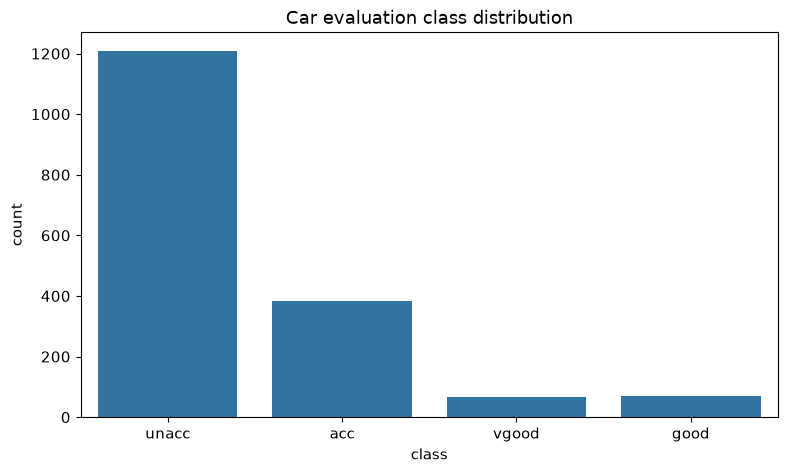

In [8]:
sns.countplot(data=cars, x='class')
plt.title('Car evaluation class distribution')
plt.show()

## Compare classifiers
One-hot encode nominal predictors inside each training fold. Compare models using training-only stratified cross-validation, then evaluate each once on a fixed holdout; do not choose a model from test scores.

,cv_accuracy,cv_macro_f1
model,,
Majority baseline,0.701,0.206
Logistic regression,0.905,0.747
KNN,0.842,0.589
Random forest,0.945,0.820
XGBoost,0.978,0.922


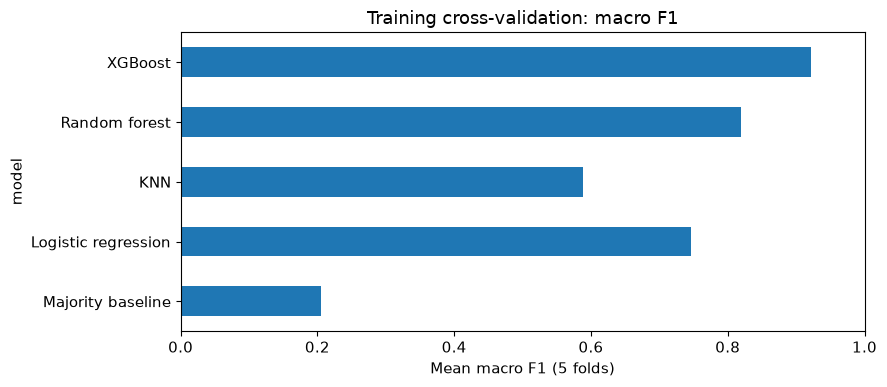

In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier
X = cars.drop(columns='class')
labels = LabelEncoder()
y = labels.fit_transform(cars['class'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': LogisticRegression(max_iter=2000),
    'KNN': KNeighborsClassifier(n_neighbors=4),
    'Random forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, n_jobs=2)
}
scores = []
fitted = {}
for name, classifier in models.items():
    pipeline = make_pipeline(OneHotEncoder(handle_unknown='ignore', sparse_output=False), classifier)
    result = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
    scores.append({'model': name, 'cv_accuracy': result['test_accuracy'].mean(), 'cv_macro_f1': result['test_f1_macro'].mean()})
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
comparison = pd.DataFrame(scores).set_index('model')
display(comparison.round(3))
comparison['cv_macro_f1'].plot.barh(figsize=(9, 4), xlim=(0, 1), title='Training cross-validation: macro F1')
plt.xlabel('Mean macro F1 (5 folds)')
plt.tight_layout()
plt.show()


Majority baseline
              precision    recall  f1-score   support

         acc       0.00      0.00      0.00       115
        good       0.00      0.00      0.00        21
       unacc       0.70      1.00      0.82       363
       vgood       0.00      0.00      0.00        20

    accuracy                           0.70       519
   macro avg       0.17      0.25      0.21       519
weighted avg       0.49      0.70      0.58       519

Logistic regression
              precision    recall  f1-score   support

         acc       0.79      0.84      0.82       115
        good       0.69      0.43      0.53        21
       unacc       0.96      0.97      0.97       363
       vgood       0.95      0.90      0.92        20

    accuracy                           0.92       519
   macro avg       0.85      0.78      0.81       519
weighted avg       0.91      0.92      0.91       519

KNN
              precision    recall  f1-score   support

         acc       0.66      0.89

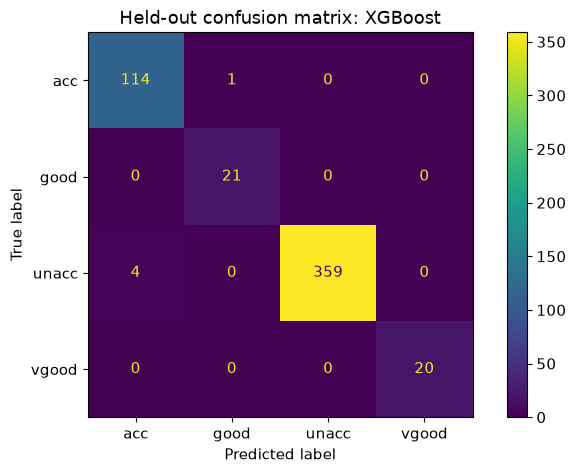

In [10]:
for name, pipeline in fitted.items():
    print(name)
    prediction = pipeline.predict(X_test)
    print(classification_report(y_test, prediction, target_names=labels.classes_, zero_division=0))
selected = comparison['cv_macro_f1'].idxmax()
ConfusionMatrixDisplay.from_predictions(y_test, fitted[selected].predict(X_test), display_labels=labels.classes_)
plt.title(f'Held-out confusion matrix: {selected}')
plt.show()
